# 🏄 SurfCast Sri Lanka
## Predicting tomorrow's *good surf days* at Arugam Bay and Hikkaduwa with Ensemble Learning

**Module:** Machine Learning, hands-on mini project (Ensemble Learning Dashboard)

### Problem and why it matters in Sri Lanka
Surf tourism is one of Sri Lanka's fastest-growing tourism niches. **Arugam Bay** (east coast) and
**Hikkaduwa** (south-west coast) bring thousands of foreign surfers every year, and local surf schools,
guesthouses, tuk-tuk drivers and board-rental shops depend on them. The two coasts have *opposite*
seasons because the monsoon winds swap sides of the island:

* **South-west monsoon (May-Sep):** wind blows *offshore* at Arugam Bay → clean waves on the east coast.
* **North-east monsoon (Nov-Mar):** wind blows *offshore* on the south-west coast → Hikkaduwa season.

**Task (binary classification):** using only what is known at the end of *today*, predict whether
**tomorrow** will be a *good surf day* at each spot. A good surf day is defined by simple surfing rules
(swell big enough but not dangerous, long wave period, swell coming from the right direction, and light or
offshore wind).

**Extra tasks:** hybrid models, **RF + SARIMA** (monthly swell forecasting) and **RF + MLP**
(daily swell-height regression).

### 🤖 AI-use declaration
> **Student:** _Dheeraka_ · **Index no.:** _[YOUR INDEX]_
>
> Parts of the code and text in this notebook (and in the dashboard, `features.py`, `download_data.py`)
> were generated with **Claude (Anthropic)**. I ran every cell, checked the outputs, and I understand the
> methods and results. All numbers in the interpretations come from actually running this notebook.

### Data source
| Item | Details |
|---|---|
| Provider | [Open-Meteo](https://open-meteo.com): free, open data, no login or API key (CC BY 4.0) |
| Wave data | Open-Meteo **Marine API**: daily max wave / swell / wind-wave height, period, dominant direction |
| Weather data | Open-Meteo **Historical Weather API** (ERA5 reanalysis): wind, gusts, rain, humidity, pressure, cloud |
| Locations | Arugam Bay (6.84 N, 81.84 E) and Hikkaduwa (6.14 N, 80.10 E), Sri Lanka |
| Period | requested 2010-01-01 → 2025-12-31; swell data available from 2021-10-02 (daily) |
| Download | `python download_data.py` (retries + caching into `data/raw/`) |

These are **model / reanalysis** data on a grid, not buoy measurements at the exact surf break.

In [1]:
import os, time, json, warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import joblib

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (BaggingClassifier, RandomForestClassifier, AdaBoostClassifier,
                              GradientBoostingClassifier, StackingClassifier, VotingClassifier,
                              RandomForestRegressor)
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import KFold, TimeSeriesSplit, RandomizedSearchCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, roc_curve, confusion_matrix,
                             mean_squared_error, mean_absolute_error, r2_score)
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from statsmodels.tsa.statespace.sarimax import SARIMAX

import features as F

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
os.makedirs("models", exist_ok=True); os.makedirs("results", exist_ok=True)
SPOT_COLORS = {"Arugam Bay": "#E07A1F", "Hikkaduwa": "#1F77B4"}

## 1. Load the data

In [2]:
raw = F.load_all()
print("Rows:", len(raw))
display(raw.groupby("spot")["time"].agg(["min", "max", "count"]))
raw.head()

Rows: 3102


,min,max,count
spot,,,
Arugam Bay,2021-10-02,2025-12-31,1551
Hikkaduwa,2021-10-02,2025-12-31,1551


,spot,time,wave_height_max,wave_direction_dominant,wave_period_max,wind_wave_height_max,wind_wave_direction_dominant,wind_wave_period_max,swell_wave_height_max,swell_wave_direction_dominant,...,weather_code,temperature_2m_max,precipitation_sum,precipitation_hours,wind_speed_10m_max,wind_gusts_10m_max,wind_direction_10m_dominant,relative_humidity_2m_mean,pressure_msl_mean,cloud_cover_mean
0,Arugam Bay,2021-10-02,1.04,170.0,13.0,0.22,200.0,2.05,1.02,168.0,...,51,29.2,0.9,8.0,10.8,30.6,174,85,1007.5,58
1,Arugam Bay,2021-10-03,1.16,172.0,13.1,0.30,209.0,2.25,1.02,168.0,...,63,29.3,9.7,13.0,14.5,49.0,186,88,1007.4,64
2,Arugam Bay,2021-10-04,1.14,173.0,11.0,0.46,206.0,2.75,0.96,170.0,...,63,31.4,8.3,4.0,13.8,38.2,217,87,1007.3,100
3,Arugam Bay,2021-10-05,1.34,175.0,10.0,0.72,206.0,3.25,1.12,166.0,...,61,29.8,4.6,6.0,23.9,54.0,210,83,1007.2,95
4,Arugam Bay,2021-10-06,1.24,177.0,8.4,0.84,204.0,3.60,0.86,164.0,...,3,31.9,0.0,0.0,26.0,58.0,211,76,1007.0,72


## 2. Exploratory data analysis (EDA)

In [3]:
raw["good_surf"] = F.good_surf(raw)
print("Missing values per column (after dropping rows without core wave data):")
print(raw.isna().sum()[raw.isna().sum() > 0].to_string() or "none")
display(raw.groupby("spot")[["swell_wave_height_max", "swell_wave_period_max", "wind_speed_10m_max",
                             "precipitation_sum", "good_surf"]].mean().round(2)
        .rename(columns={"good_surf": "good_surf_rate"}))

Missing values per column (after dropping rows without core wave data):
Series([], )


,swell_wave_height_max,swell_wave_period_max,wind_speed_10m_max,precipitation_sum,good_surf_rate
spot,,,,,
Arugam Bay,0.85,9.94,17.58,5.44,0.40
Hikkaduwa,1.29,10.66,16.86,9.18,0.13


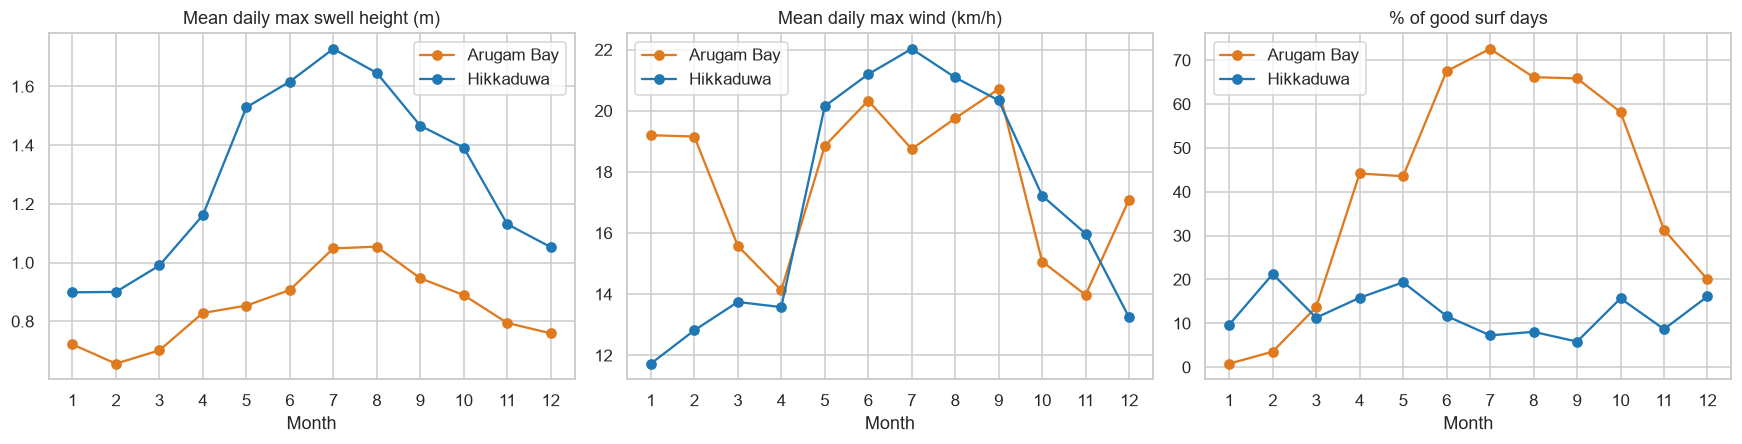

In [4]:
raw["month"] = raw["time"].dt.month
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for spot, d in raw.groupby("spot"):
    m = d.groupby("month")
    axes[0].plot(m["swell_wave_height_max"].mean(), marker="o", label=spot, color=SPOT_COLORS[spot])
    axes[1].plot(m["wind_speed_10m_max"].mean(), marker="o", label=spot, color=SPOT_COLORS[spot])
    axes[2].plot(m["good_surf"].mean() * 100, marker="o", label=spot, color=SPOT_COLORS[spot])
axes[0].set_title("Mean daily max swell height (m)"); axes[1].set_title("Mean daily max wind (km/h)")
axes[2].set_title("% of good surf days")
for a in axes: a.set_xticks(range(1, 13)); a.set_xlabel("Month"); a.legend()
plt.tight_layout(); plt.show()

**Interpretation.** The see-saw between the two coasts is clear. Arugam Bay has good surf on 66-73% of days in June to
September and almost none in January (1%) and February (4%), because the south-west monsoon blows westerly, which is
offshore on the east coast. Hikkaduwa is the opposite: its best month is February (21%) and it drops to 6-8% in
July to September, when the same monsoon blows onshore and makes the sea messy. Hikkaduwa actually gets *bigger* swell
on average (1.29 m vs 0.85 m) but is good less often (13% vs 40% of days), which shows that size alone does not make a
good surf day: direction, period and wind matter just as much.

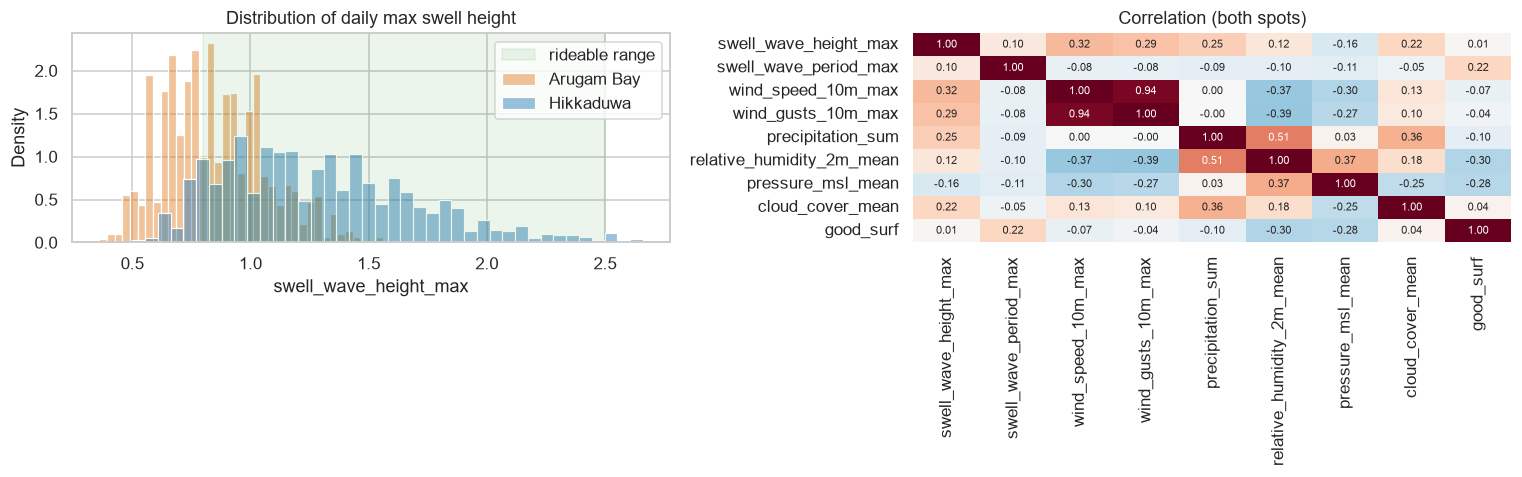

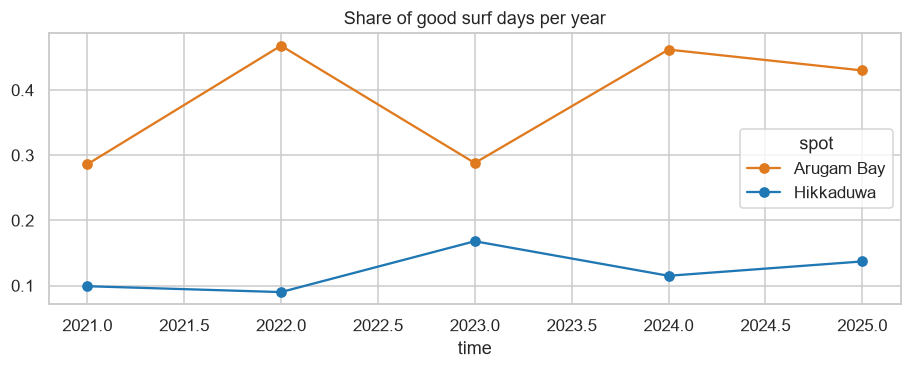

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for spot, d in raw.groupby("spot"):
    sns.histplot(d["swell_wave_height_max"], bins=40, ax=axes[0], color=SPOT_COLORS[spot], label=spot,
                 stat="density", alpha=0.45)
axes[0].axvspan(F.RULES["swell_min_m"], F.RULES["swell_max_m"], color="green", alpha=0.08, label="rideable range")
axes[0].set_title("Distribution of daily max swell height"); axes[0].legend()
cols = ["swell_wave_height_max", "swell_wave_period_max", "wind_speed_10m_max", "wind_gusts_10m_max",
        "precipitation_sum", "relative_humidity_2m_mean", "pressure_msl_mean", "cloud_cover_mean", "good_surf"]
cols = [c for c in cols if c in raw.columns]
sns.heatmap(raw[cols].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=axes[1],
            annot_kws={"size": 7}, cbar=False)
axes[1].set_title("Correlation (both spots)")
plt.tight_layout(); plt.show()
yearly = raw.groupby([raw["time"].dt.year, "spot"])["good_surf"].mean().unstack().round(3)
yearly.plot(figsize=(10, 3.2), marker="o", color=[SPOT_COLORS[c] for c in yearly.columns],
            title="Share of good surf days per year"); plt.show()

**Interpretation.** Swell height is spread widely and much of Hikkaduwa's swell is above the rideable 0.8-2.5 m band during the
monsoon. In the correlation table, no single variable is strongly linked to `good_surf` (swell period +0.22, wind
speed -0.07, swell height +0.01). The label is a non-linear AND of several conditions, so a linear model on one
variable cannot capture it, which is why tree ensembles are a good fit. The share of good days changes from year to
year (Arugam Bay 29% in 2023 vs 46% in 2024), so the test year can differ from the training years.

## 3. Feature engineering (`features.py`)
All features use **only information available at the end of today**, so nothing about tomorrow leaks in:

* **Today's conditions:** swell/wave/wind-wave height and period, wind speed and gusts, rain, humidity, pressure, cloud.
* **Circular variables → sin/cos:** month, day-of-year and every direction (swell, wave, wind). This way 359° and 1° end up close together.
* **Surf physics:** the *offshore wind component* (wind speed × cos(angle to the offshore direction)),
  the *swell alignment* with the break, and a wave-energy proxy (H² × T).
* **History:** yesterday's swell and wind, 2-day lag, 3- and 7-day rolling means, pressure change, and
  whether *today* was a good day (persistence) plus the share of good days in the last week.
* **Target:** `good_surf_tomorrow` (shifted by −1 day within each spot; rows with date gaps are removed).

In [6]:
data, FEATS = F.build_dataset(raw.drop(columns=["good_surf", "month"]))
print(f"{len(data)} rows × {len(FEATS)} features")
print(FEATS)

3086 rows × 41 features
['swell_wave_height_max', 'swell_wave_period_max', 'wave_height_max', 'wave_period_max', 'wind_wave_height_max', 'wind_wave_period_max', 'wind_speed_10m_max', 'wind_gusts_10m_max', 'precipitation_sum', 'precipitation_hours', 'temperature_2m_max', 'relative_humidity_2m_mean', 'pressure_msl_mean', 'cloud_cover_mean', 'swell_wave_direction_dominant_sin', 'swell_wave_direction_dominant_cos', 'wave_direction_dominant_sin', 'wave_direction_dominant_cos', 'wind_wave_direction_dominant_sin', 'wind_wave_direction_dominant_cos', 'wind_direction_10m_dominant_sin', 'wind_direction_10m_dominant_cos', 'month_sin', 'month_cos', 'doy_sin', 'doy_cos', 'offshore_wind_component', 'swell_alignment', 'wave_energy_proxy', 'is_arugam', 'good_surf', 'good_surf_roll7', 'swell_h_lag1', 'swell_h_lag2', 'swell_h_change', 'swell_p_lag1', 'wind_lag1', 'pressure_change', 'swell_h_roll3', 'swell_h_roll7', 'wind_roll3']


## 4. Train/test split by **time**
A random split would put e.g. 14 March in training and 15 March in testing. Neighbouring days are almost
identical, so the test score would be too optimistic (leakage). Instead we **train on the older years and test on the
most recent full year (2025)**.

In [7]:
train, test, TEST_START = F.time_split(data, test_years=1)
X_train, y_train = train[FEATS], train["good_surf_tomorrow"]
X_test, y_test = test[FEATS], test["good_surf_tomorrow"]
print(f"Train: {train.time.min().date()} → {train.time.max().date()}  ({len(train)} rows)")
print(f"Test : {test.time.min().date()} → {test.time.max().date()}  ({len(test)} rows)")
print(f"Positive rate: train {y_train.mean():.3f} | test {y_test.mean():.3f}")

Train: 2021-10-08 → 2024-12-31  (2358 rows)
Test : 2025-01-01 → 2025-12-30  (728 rows)
Positive rate: train 0.259 | test 0.284


**Interpretation.** Training covers Oct 2021 to Dec 2024 (2,358 spot-days) and the test set is the whole of 2025 (728 spot-days).
About 26% of training days and 28% of test days are good, so the classes are imbalanced and accuracy alone would be
misleading. **Note on data length:** Open-Meteo's marine API only provides swell height/period/direction from
October 2021 (earlier years come back empty), so the usable history is about 4 years instead of 16 and the test set
is the most recent full year rather than three years.

## 5. Models
| Family | Model | Idea |
|---|---|---|
| Baseline | Persistence ("tomorrow = today") | A naive forecast. Any ML model must beat this |
| Baseline | Single Decision Tree (no depth limit) | Low bias, **high variance** (overfits) |
| **Bagging** | Bagged Trees (200 trees) | Bootstrap samples + averaging → **lower variance** |
| **Bagging** | Random Forest (500 trees, m = √p) | Bagging + random feature subsets → de-correlated trees |
| **Boosting** | AdaBoost (stumps) | Re-weights misclassified days → **lower bias** |
| **Boosting** | Gradient Boosting | Each new tree fits the errors (gradients) of the previous ones |
| **Boosting** | XGBoost | Regularised, fast gradient boosting |
| **Boosting** | LightGBM | Leaf-wise, histogram-based gradient boosting |
| **Stacking** | RF + XGB + LGBM + LogReg → LogReg meta-model | Meta-model learns how to combine base models |
| **Voting** | Soft voting (RF, GB, XGB, LGBM) | Average of predicted probabilities |

In [8]:
blocked_cv = KFold(n_splits=5, shuffle=False)   # contiguous time blocks (data is time-ordered)
def base_models():
    return {
        "Decision Tree": DecisionTreeClassifier(random_state=SEED),
        "Bagged Trees": BaggingClassifier(DecisionTreeClassifier(random_state=SEED), n_estimators=200,
                                          oob_score=True, n_jobs=1, random_state=SEED),
        "Random Forest": RandomForestClassifier(n_estimators=500, max_features="sqrt", min_samples_leaf=2,
                                                oob_score=True, n_jobs=1, random_state=SEED),
        "AdaBoost": AdaBoostClassifier(n_estimators=300, learning_rate=0.5, random_state=SEED),
        "Gradient Boosting": GradientBoostingClassifier(n_estimators=300, learning_rate=0.05, max_depth=3,
                                                        random_state=SEED),
        "XGBoost": XGBClassifier(n_estimators=400, learning_rate=0.05, max_depth=4, subsample=0.8,
                                 colsample_bytree=0.8, eval_metric="logloss", n_jobs=1, random_state=SEED),
        "LightGBM": LGBMClassifier(n_estimators=400, learning_rate=0.05, num_leaves=31, subsample=0.8,
                                   subsample_freq=1, colsample_bytree=0.8, random_state=SEED, verbose=-1),
    }
models = base_models()
stack_base = [("rf", RandomForestClassifier(n_estimators=300, min_samples_leaf=2, n_jobs=1, random_state=SEED)),
              ("xgb", XGBClassifier(n_estimators=400, learning_rate=0.05, max_depth=4, subsample=0.8,
                                    colsample_bytree=0.8, eval_metric="logloss", n_jobs=1, random_state=SEED)),
              ("lgbm", LGBMClassifier(n_estimators=400, learning_rate=0.05, random_state=SEED, verbose=-1)),
              ("lr", make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)))]
models["Stacking"] = StackingClassifier(stack_base, final_estimator=LogisticRegression(max_iter=2000),
                                        cv=blocked_cv, stack_method="predict_proba", n_jobs=1)
models["Soft Voting"] = VotingClassifier(
    [("rf", RandomForestClassifier(n_estimators=300, min_samples_leaf=2, n_jobs=1, random_state=SEED)),
     ("gb", GradientBoostingClassifier(n_estimators=300, learning_rate=0.05, max_depth=3, random_state=SEED)),
     ("xgb", XGBClassifier(n_estimators=400, learning_rate=0.05, max_depth=4, subsample=0.8,
                           colsample_bytree=0.8, eval_metric="logloss", n_jobs=1, random_state=SEED)),
     ("lgbm", LGBMClassifier(n_estimators=400, learning_rate=0.05, random_state=SEED, verbose=-1))],
    voting="soft", n_jobs=1)

rows, proba_test, proba_train = [], {}, {}
def evaluate(name, p_tr, p_te, secs):
    yhat_te, yhat_tr = (p_te >= 0.5).astype(int), (p_tr >= 0.5).astype(int)
    rows.append({"Model": name, "Accuracy": accuracy_score(y_test, yhat_te),
                 "Precision": precision_score(y_test, yhat_te, zero_division=0),
                 "Recall": recall_score(y_test, yhat_te), "F1": f1_score(y_test, yhat_te),
                 "ROC-AUC": roc_auc_score(y_test, p_te), "PR-AUC": average_precision_score(y_test, p_te),
                 "Train accuracy": accuracy_score(y_train, yhat_tr), "Train F1": f1_score(y_train, yhat_tr),
                 "Train time (s)": secs})
    proba_test[name], proba_train[name] = p_te, p_tr

# naive persistence baseline
evaluate("Persistence (baseline)", train["good_surf"].values.astype(float), test["good_surf"].values.astype(float), 0.0)
for name, mdl in models.items():
    t0 = time.perf_counter(); mdl.fit(X_train, y_train); secs = time.perf_counter() - t0
    evaluate(name, mdl.predict_proba(X_train)[:, 1], mdl.predict_proba(X_test)[:, 1], secs)
    print(f"{name:<18} trained in {secs:6.1f}s")

Decision Tree      trained in    0.1s


Bagged Trees       trained in    7.6s


Random Forest      trained in    3.2s


AdaBoost           trained in    2.0s


Gradient Boosting  trained in    3.9s


XGBoost            trained in    0.7s


LightGBM           trained in    0.4s


Stacking           trained in   16.1s


Soft Voting        trained in    7.5s


## 6. Results: metrics table (test set = most recent full year (2025), threshold 0.5)

In [9]:
metrics = pd.DataFrame(rows).set_index("Model")
display(metrics.drop(columns=["Train accuracy", "Train F1"]).style.format("{:.3f}")
        .highlight_max(subset=["Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "PR-AUC"], color="#c7f0d0"))

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Train time (s)
Model,,,,,,,
Persistence (baseline),0.810,0.667,0.667,0.667,0.767,0.539,0.000
Decision Tree,0.769,0.587,0.638,0.611,0.730,0.477,0.060
Bagged Trees,0.835,0.730,0.667,0.697,0.882,0.784,7.610
Random Forest,0.845,0.767,0.652,0.705,0.883,0.791,3.163
AdaBoost,0.830,0.727,0.643,0.682,0.859,0.750,1.981
Gradient Boosting,0.835,0.723,0.681,0.701,0.874,0.758,3.949
XGBoost,0.819,0.687,0.667,0.676,0.876,0.780,0.733
LightGBM,0.817,0.685,0.662,0.673,0.872,0.775,0.366
Stacking,0.838,0.746,0.652,0.696,0.885,0.787,16.086


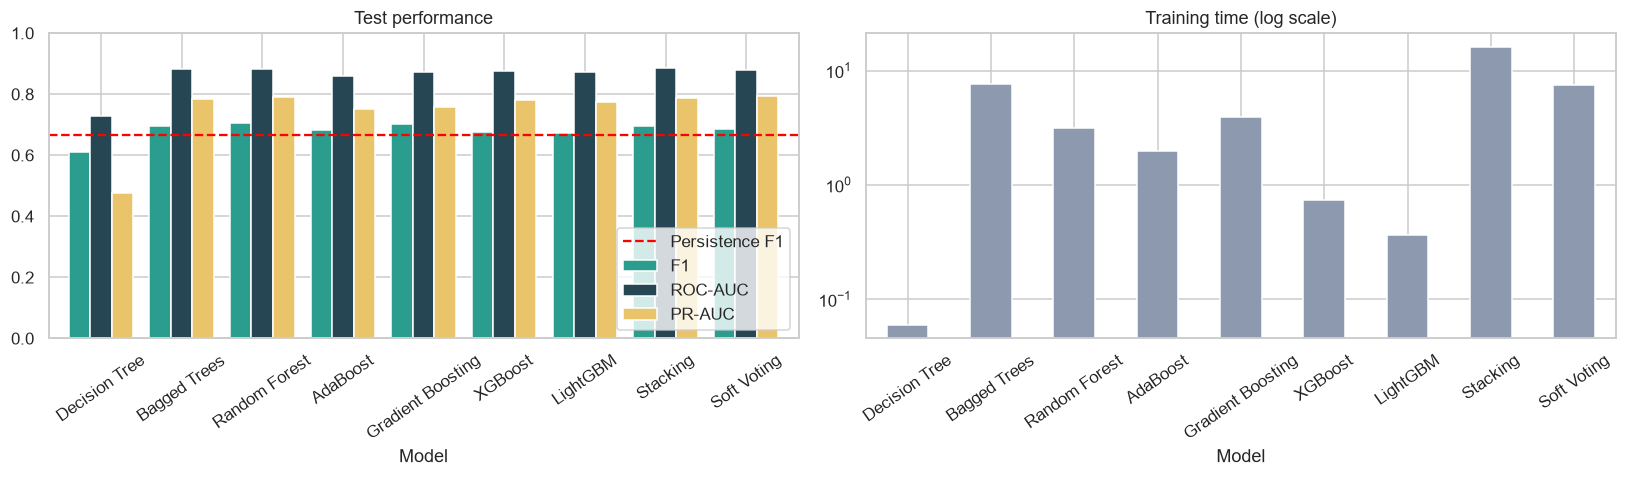

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
m = metrics.drop(index="Persistence (baseline)")
m[["F1", "ROC-AUC", "PR-AUC"]].plot.bar(ax=axes[0], width=0.8, color=["#2a9d8f", "#264653", "#e9c46a"])
axes[0].axhline(metrics.loc["Persistence (baseline)", "F1"], ls="--", c="red", label="Persistence F1")
axes[0].set_ylim(0, 1); axes[0].set_title("Test performance"); axes[0].legend(loc="lower right")
axes[0].tick_params(axis="x", rotation=35)
m["Train time (s)"].plot.bar(ax=axes[1], color="#8d99ae", logy=True)
axes[1].set_title("Training time (log scale)"); axes[1].tick_params(axis="x", rotation=35)
plt.tight_layout(); plt.show()

**Interpretation.** All ensembles beat the single decision tree (F1 0.611), and the bagging/boosting/stacking models beat the
persistence baseline on F1 (0.667) and especially on ranking quality (ROC-AUC 0.77 → 0.86-0.89). **Random Forest** is
the best by F1 (0.705) and accuracy (0.845); Stacking has the highest ROC-AUC (0.885) and Soft Voting the highest
PR-AUC (0.792). The differences between the top ensembles are small (F1 0.67-0.71), which is expected because they all
learn from the same features. Persistence is a strong baseline here because surf conditions change slowly from one day
to the next.

## 7. Bias, variance and irreducible error
Expected test error = **Bias²** + **Variance** + **Irreducible error**.
* A deep single tree has low bias but **high variance**: a big gap between train and test.
* **Bagging/RF** average many high-variance trees → the variance (and the gap) drops.
* **Boosting** starts from weak, high-bias learners and adds them one after another → the bias drops.
* **Irreducible error**: the data itself is noisy (gridded model data, sudden local winds), so no model reaches 100%.

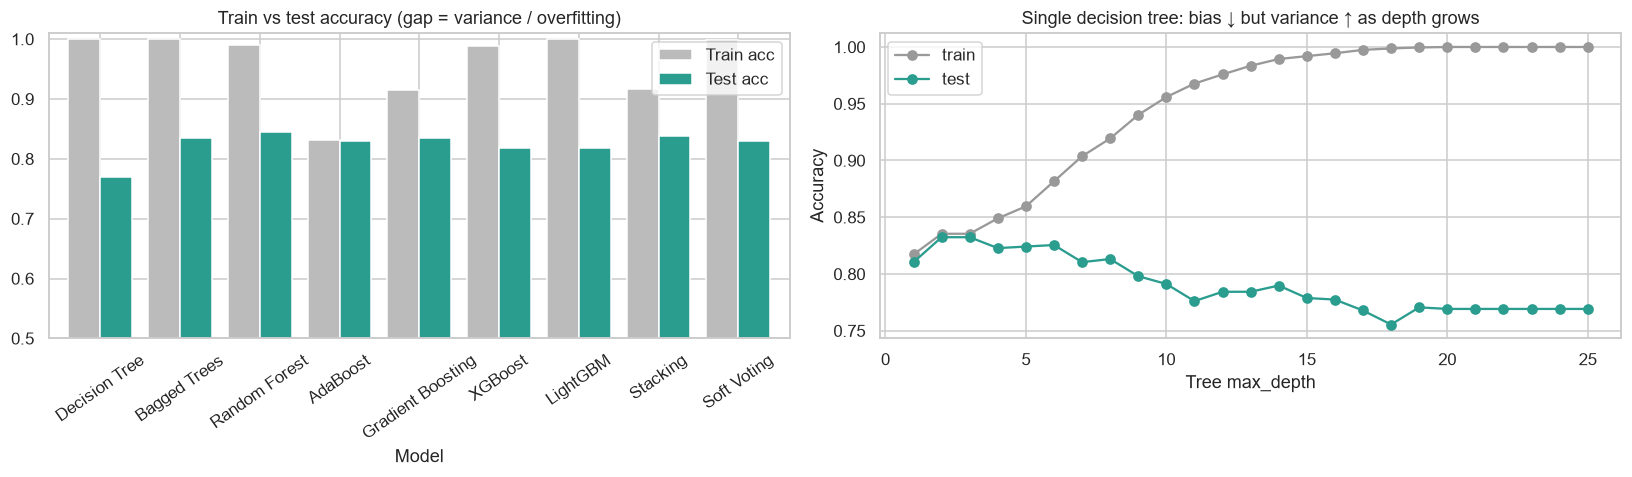

,Train acc,Test acc,Train F1,Test F1,Acc gap
Model,,,,,
Decision Tree,1.000,0.769,1.000,0.611,0.231
Bagged Trees,1.000,0.835,1.000,0.697,0.165
Random Forest,0.989,0.845,0.979,0.705,0.145
AdaBoost,0.831,0.830,0.643,0.682,0.002
Gradient Boosting,0.914,0.835,0.825,0.701,0.079
XGBoost,0.988,0.819,0.976,0.676,0.169
LightGBM,1.000,0.817,1.000,0.673,0.183
Stacking,0.916,0.838,0.827,0.696,0.079
Soft Voting,0.999,0.830,0.998,0.687,0.169


In [11]:
gap = metrics.drop(index="Persistence (baseline)")[["Train accuracy", "Accuracy", "Train F1", "F1"]]
gap.columns = ["Train acc", "Test acc", "Train F1", "Test F1"]
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
gap[["Train acc", "Test acc"]].plot.bar(ax=axes[0], color=["#bbbbbb", "#2a9d8f"], width=0.8)
axes[0].set_ylim(0.5, 1.01); axes[0].set_title("Train vs test accuracy (gap = variance / overfitting)")
axes[0].tick_params(axis="x", rotation=35)
depths, tr_acc, te_acc = range(1, 26), [], []
for d in depths:
    dt = DecisionTreeClassifier(max_depth=d, random_state=SEED).fit(X_train, y_train)
    tr_acc.append(accuracy_score(y_train, dt.predict(X_train))); te_acc.append(accuracy_score(y_test, dt.predict(X_test)))
axes[1].plot(depths, tr_acc, "o-", label="train", color="#999"); axes[1].plot(depths, te_acc, "o-", label="test", color="#2a9d8f")
axes[1].set_xlabel("Tree max_depth"); axes[1].set_ylabel("Accuracy")
axes[1].set_title("Single decision tree: bias ↓ but variance ↑ as depth grows"); axes[1].legend()
plt.tight_layout(); plt.show()
gap["Acc gap"] = gap["Train acc"] - gap["Test acc"]
display(gap.round(3))
dt_depth = pd.DataFrame({"max_depth": list(depths), "train_acc": tr_acc, "test_acc": te_acc})

**Interpretation.** The fully grown Decision Tree and the Bagged Trees both reach 100% training accuracy, but the tree falls to
76.9% on test (a 23-point gap, high variance) while bagging keeps 83.5% (gap 16.5): averaging 200 bootstrap trees
removes much of the variance. Random Forest narrows the gap further (14.5) by de-correlating the trees. AdaBoost has
almost no gap (0.2) because its stumps are high-bias learners, and Gradient Boosting / Stacking sit in between (≈8).
The depth curve shows the classic trade-off: test accuracy peaks at depth 2-3 (83.2%) and falls to ≈78% as the tree
grows, while training accuracy keeps rising to 100%. The remaining ≈15% error is largely irreducible noise
(gridded model data, local winds and tide that the data do not contain).

## 8. ROC curves and confusion matrices

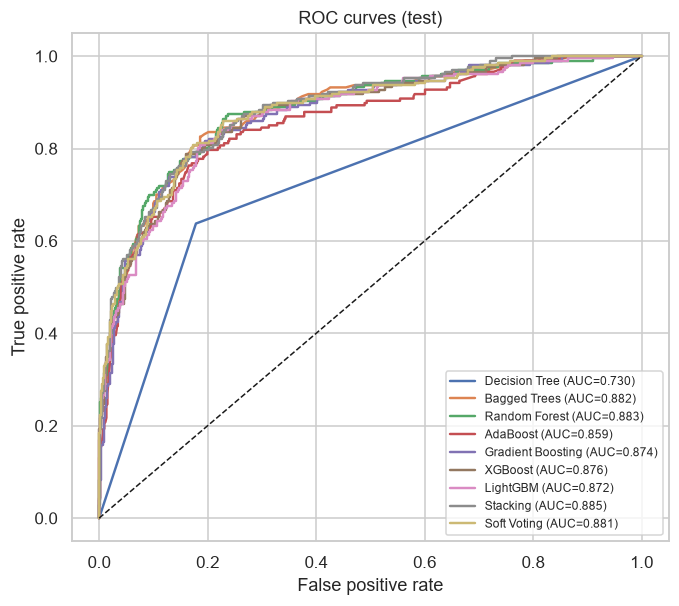

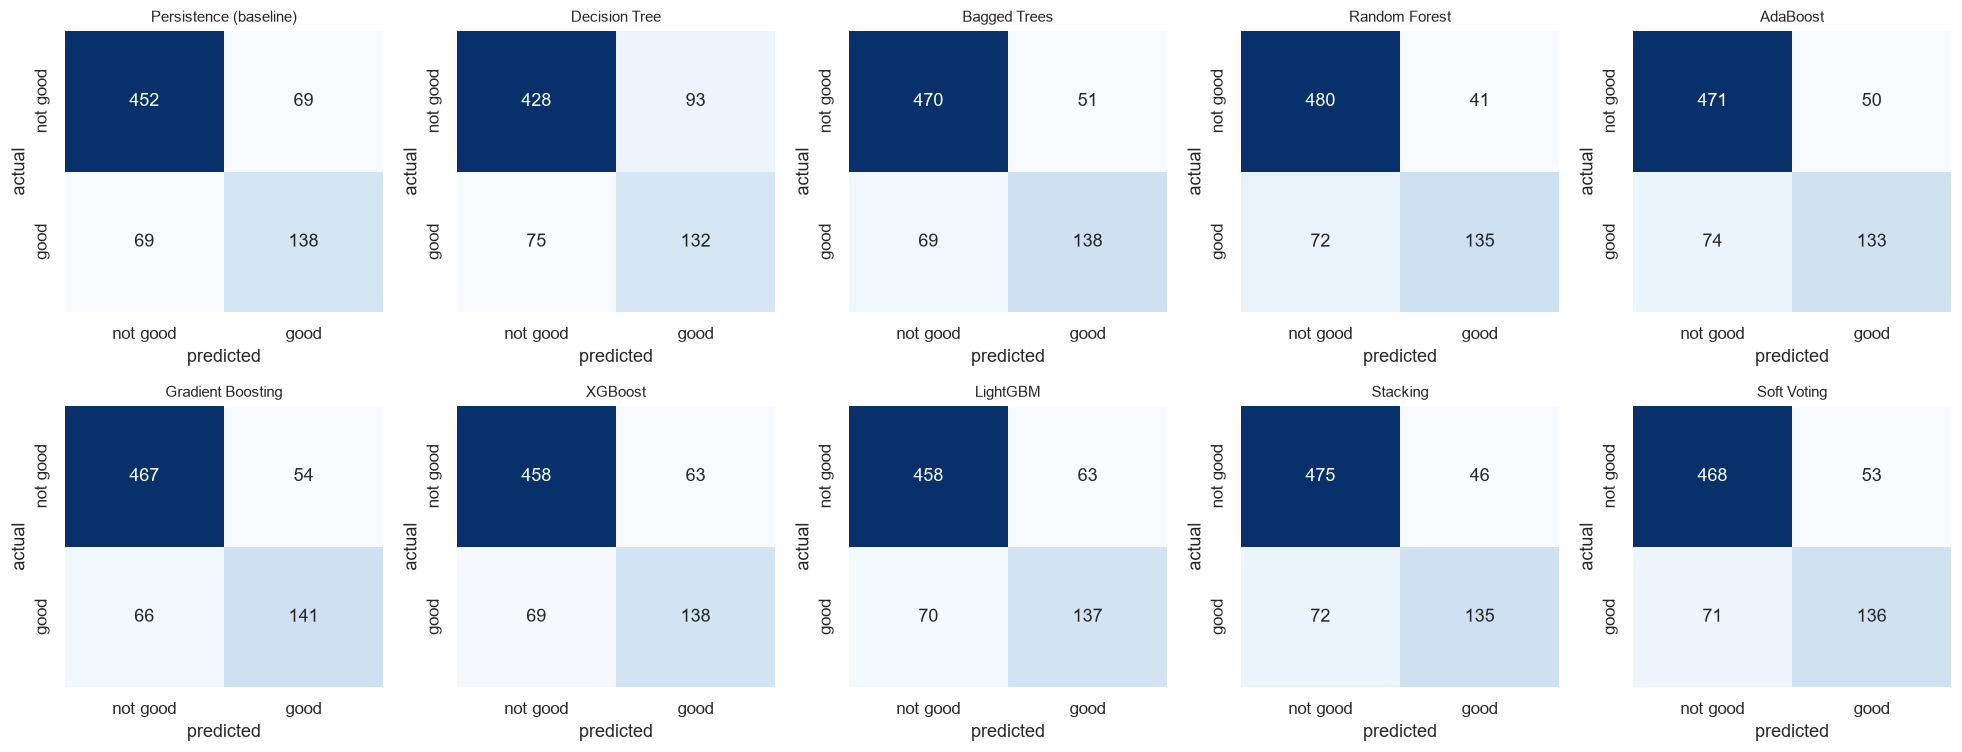

In [12]:
fig, ax = plt.subplots(figsize=(7, 6))
for name, p in proba_test.items():
    if name.startswith("Persistence"): continue
    fpr, tpr, _ = roc_curve(y_test, p)
    ax.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, p):.3f})", lw=1.6)
ax.plot([0, 1], [0, 1], "k--", lw=1); ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.set_title("ROC curves (test)"); ax.legend(fontsize=8); plt.show()

names = [n for n in proba_test if not n.startswith("Persistence")]
fig, axes = plt.subplots(2, 5, figsize=(18, 7))
for ax, name in zip(axes.ravel(), ["Persistence (baseline)"] + names):
    cm = confusion_matrix(y_test, (proba_test[name] >= 0.5).astype(int))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["not good", "good"], yticklabels=["not good", "good"])
    ax.set_title(name, fontsize=10); ax.set_xlabel("predicted"); ax.set_ylabel("actual")
plt.tight_layout(); plt.show()

**Interpretation.** The ROC curves of all ensembles lie close together (AUC 0.86-0.89) and well above the single tree (0.73).
The confusion matrices show the typical error: most mistakes are missed good days (false negatives), so recall
(≈0.65) is lower than precision (≈0.72-0.77) at the default 0.5 threshold.

## 9. Inside Random Forest: Out-of-Bag (OOB) error
Each bootstrap sample leaves out about 37% of the rows (the *out-of-bag* rows). Predicting each row only with the trees
that did **not** see it gives a free validation error without a separate validation set.

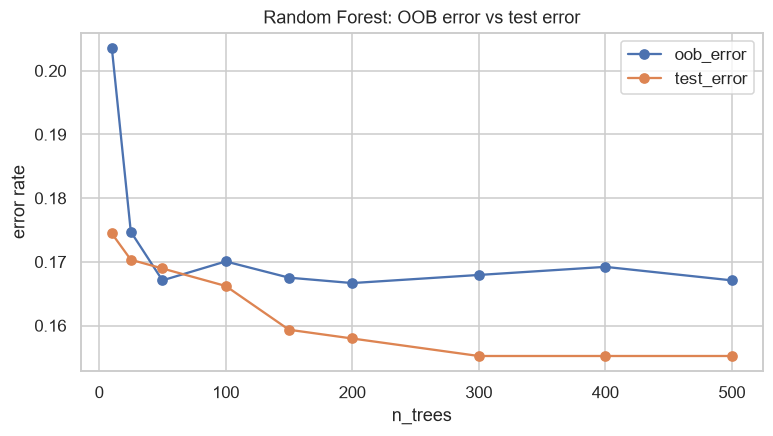

,n_trees,oob_error,test_error
0,10,0.2036,0.1745
1,25,0.1747,0.1703
2,50,0.1671,0.1690
3,100,0.1701,0.1662
4,150,0.1675,0.1593
5,200,0.1667,0.1580
6,300,0.1679,0.1552
7,400,0.1692,0.1552
8,500,0.1671,0.1552


In [13]:
n_list = [10, 25, 50, 100, 150, 200, 300, 400, 500]
rf_w = RandomForestClassifier(warm_start=True, oob_score=True, max_features="sqrt", min_samples_leaf=2,
                              n_jobs=1, random_state=SEED)
oob_rows = []
for n in n_list:
    rf_w.set_params(n_estimators=n); rf_w.fit(X_train, y_train)
    oob_rows.append({"n_trees": n, "oob_error": 1 - rf_w.oob_score_,
                     "test_error": 1 - accuracy_score(y_test, rf_w.predict(X_test))})
oob_curve = pd.DataFrame(oob_rows)
ax = oob_curve.plot(x="n_trees", y=["oob_error", "test_error"], marker="o", figsize=(8, 4),
                    title="Random Forest: OOB error vs test error"); ax.set_ylabel("error rate"); plt.show()
display(oob_curve.round(4))

**Interpretation.** The OOB error drops quickly from 0.204 with 10 trees to about 0.167 with 50 trees and then stays flat,
while the test error keeps slowly falling to 0.155 at 300-500 trees. Adding trees never hurts a Random Forest (it does
not overfit by adding trees), it only costs time. The OOB error is a good, free estimate of the test error (within
about 1 percentage point) without needing a separate validation set.

## 10. Inside Random Forest: number of features per split (*m* = `max_features`)
At every split RF looks at only *m* random features out of *p*. Small *m* → trees are more different (de-correlated)
but individually weaker. **m = p means every split sees all features, which is plain bagging.**

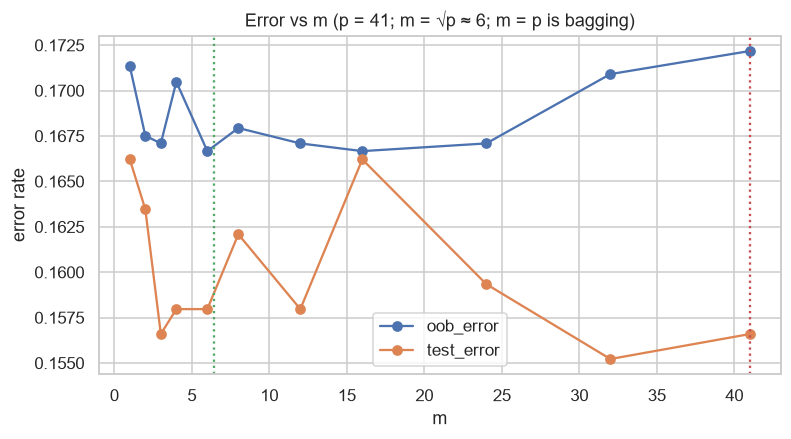

,m,oob_error,test_error
0,1,0.1713,0.1662
1,2,0.1675,0.1635
2,3,0.1671,0.1566
3,4,0.1705,0.1580
4,6,0.1667,0.1580
5,8,0.1679,0.1621
6,12,0.1671,0.1580
7,16,0.1667,0.1662
8,24,0.1671,0.1593
9,32,0.1709,0.1552


In [14]:
p = len(FEATS)
m_list = sorted(set([1, 2, 3, 4, 6, int(np.sqrt(p)), 8, 12, 16, 24, 32, p]))
m_list = [m for m in m_list if m <= p]
m_rows = []
for m_ in m_list:
    rf_m = RandomForestClassifier(n_estimators=200, max_features=m_, min_samples_leaf=2, oob_score=True,
                                  n_jobs=1, random_state=SEED).fit(X_train, y_train)
    m_rows.append({"m": m_, "oob_error": 1 - rf_m.oob_score_,
                   "test_error": 1 - accuracy_score(y_test, rf_m.predict(X_test))})
m_curve = pd.DataFrame(m_rows)
ax = m_curve.plot(x="m", y=["oob_error", "test_error"], marker="o", figsize=(8, 4),
                  title=f"Error vs m (p = {p}; m = √p ≈ {int(np.sqrt(p))}; m = p is bagging)")
ax.axvline(np.sqrt(p), ls=":", c="g"); ax.axvline(p, ls=":", c="r"); ax.set_ylabel("error rate"); plt.show()
display(m_curve.round(4))

**Interpretation.** The error is very flat across *m*: OOB error stays between 0.167 and 0.172 and test error between 0.155 and
0.166. *m* = 3 gives one of the lowest test errors (0.157), and *m* = p = 41 (plain bagging) has the highest OOB error
(0.172). The gain from de-correlating trees is small here because a few strong features (today's label, swell
alignment, swell period) dominate, so most trees end up using them whatever *m* is.

## 11. Variable importance: RF Gini importance vs XGBoost gain

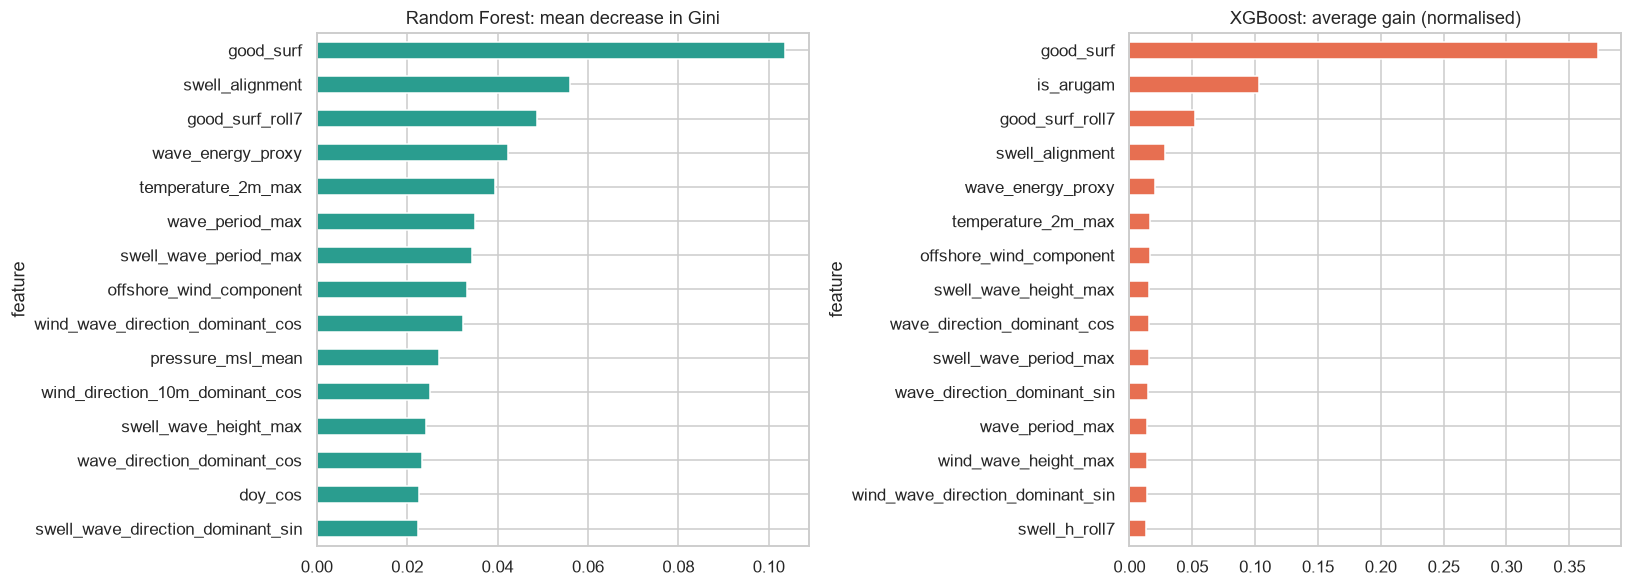

,feature,RF_gini,XGB_gain
0,good_surf,0.1037,0.3728
1,swell_alignment,0.0561,0.0280
2,good_surf_roll7,0.0488,0.0520
3,wave_energy_proxy,0.0424,0.0207
4,temperature_2m_max,0.0395,0.0162
5,wave_period_max,0.0349,0.0141
6,swell_wave_period_max,0.0344,0.0153
7,offshore_wind_component,0.0331,0.0161
8,wind_wave_direction_dominant_cos,0.0324,0.0115
9,pressure_msl_mean,0.0269,0.0122


In [15]:
rf, xgb = models["Random Forest"], models["XGBoost"]
gain = xgb.get_booster().get_score(importance_type="gain")
imp = pd.DataFrame({"feature": FEATS, "RF_gini": rf.feature_importances_,
                    "XGB_gain": [gain.get(f, 0.0) for f in FEATS]})
imp["XGB_gain"] = imp["XGB_gain"] / imp["XGB_gain"].sum()
imp = imp.sort_values("RF_gini", ascending=False).reset_index(drop=True)
top = imp.head(15).set_index("feature")
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=False)
top["RF_gini"].iloc[::-1].plot.barh(ax=axes[0], color="#2a9d8f"); axes[0].set_title("Random Forest: mean decrease in Gini")
imp.sort_values("XGB_gain", ascending=False).head(15).set_index("feature")["XGB_gain"].iloc[::-1]\
   .plot.barh(ax=axes[1], color="#e76f51"); axes[1].set_title("XGBoost: average gain (normalised)")
plt.tight_layout(); plt.show()
display(imp.head(15).round(4))

**Interpretation.** Both models agree that **today's good-surf label** is by far the most important feature (RF 10% of Gini
importance, XGBoost 37% of gain), followed by the 7-day share of good days, swell alignment, the wave-energy proxy and
swell period. XGBoost concentrates its gain on the persistence features much more than RF, because boosting greedily
picks the single best split first, while RF's random feature subsets spread importance across correlated variables
(e.g. several wave-period and direction features). Physically this makes sense: whether the swell is pointing into
the break and how long its period is matter more than raw height.

## 12. Stacking: what the meta-model learned, and a CV lesson
The meta-model (logistic regression) gets the base models' out-of-fold probabilities. Its coefficients show how much it
trusts each base model. We also refit stacking with a **shuffled** K-fold to see how leakage between neighbouring days
can mislead the meta-model on time-ordered data.

In [16]:
st = models["Stacking"]
coef = pd.Series(st.final_estimator_.coef_.ravel(), index=[n for n, _ in stack_base]).round(3)
print("Meta-model coefficients (blocked CV):"); print(coef.to_string())
st_shuf = StackingClassifier(stack_base, final_estimator=LogisticRegression(max_iter=2000),
                             cv=KFold(5, shuffle=True, random_state=SEED), stack_method="predict_proba", n_jobs=1)
st_shuf.fit(X_train, y_train)
p_sh = st_shuf.predict_proba(X_test)[:, 1]
coef_sh = pd.Series(st_shuf.final_estimator_.coef_.ravel(), index=[n for n, _ in stack_base]).round(3)
print("\nMeta-model coefficients (shuffled CV):"); print(coef_sh.to_string())
stack_cmp = pd.DataFrame({
    "Stacking (blocked CV)": [f1_score(y_test, proba_test["Stacking"] >= .5), roc_auc_score(y_test, proba_test["Stacking"])],
    "Stacking (shuffled CV)": [f1_score(y_test, p_sh >= .5), roc_auc_score(y_test, p_sh)]}, index=["F1", "ROC-AUC"]).T
display(stack_cmp.round(4))

Meta-model coefficients (blocked CV):
rf      3.194
xgb     0.736
lgbm   -0.390
lr      2.452



Meta-model coefficients (shuffled CV):
rf      3.122
xgb     1.294
lgbm   -1.075
lr      2.466


,F1,ROC-AUC
Stacking (blocked CV),0.6959,0.8852
Stacking (shuffled CV),0.6959,0.8850


**Interpretation.** The meta-model trusts the **Random Forest** most (coefficient 3.19) and the logistic regression second
(2.45), which adds a smooth linear view that the trees lack. LightGBM gets a small negative weight (-0.39) because it
is highly correlated with XGBoost, so the meta-model uses it as a correction. With shuffled K-fold the coefficients
shift (XGB 0.74 → 1.29, LGBM -0.39 → -1.08), showing that leakage between neighbouring days changes what the
meta-model learns, even though in this dataset the test scores stay the same (F1 0.696, ROC-AUC 0.885). Blocked CV is
still the honest choice for time-ordered data.

### Bagging vs Boosting vs Stacking
| | **Bagging** | **Boosting** | **Stacking** |
|---|---|---|---|
| Approach | Train many models **in parallel** on bootstrap samples | Train models **sequentially**, each fixing the previous errors | Train different models, then a **meta-model** on their predictions |
| Base models | Usually the same type (deep trees) | Usually the same type (shallow trees / stumps) | Different types (RF, XGB, LGBM, LogReg …) |
| Main goal | Reduce **variance** | Reduce **bias** (and variance with shrinkage) | Get the best of different models |
| Combination | Majority vote / average | Weighted sum of learners | Learned by the meta-model |
| Overfitting risk | Low | Higher if too many rounds / high learning rate | Meta-model can over-trust one base model |
| Examples here | Bagged Trees, Random Forest | AdaBoost, Gradient Boosting, XGBoost, LightGBM | StackingClassifier (+ Soft Voting) |

## 13. Choosing the metric (accuracy vs recall vs F1) and the decision threshold
* **Accuracy** can look good just by predicting "not good" on most days when good days are the minority.
* **Recall** = share of real good days that we caught. A surf school that cancels lessons on a good day loses money.
* **Precision** = when we say "good", how often it really is good. False alarms make tourists travel for nothing.
* **F1** balances precision and recall, so it is our main metric. ROC-AUC/PR-AUC measure ranking quality at any threshold.

The 0.5 threshold is not special. Moving it trades precision against recall (the dashboard has a live slider for this):

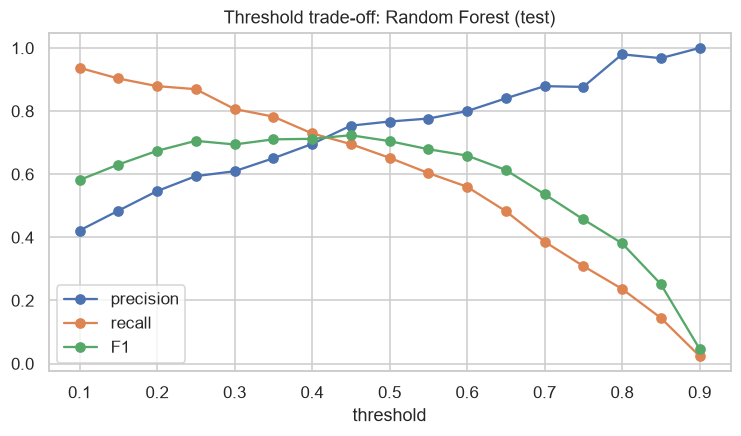

Best model by F1: Random Forest


,threshold,precision,recall,F1
0,0.10,0.422,0.937,0.582
1,0.15,0.484,0.903,0.631
2,0.20,0.547,0.879,0.674
3,0.25,0.594,0.870,0.706
4,0.30,0.609,0.807,0.694
5,0.35,0.651,0.783,0.711
6,0.40,0.696,0.729,0.712
7,0.45,0.754,0.696,0.724
8,0.50,0.767,0.652,0.705
9,0.55,0.776,0.604,0.679


In [17]:
best_name = metrics.drop(index="Persistence (baseline)")["F1"].idxmax()
pb = proba_test[best_name]
ths = np.round(np.arange(0.1, 0.91, 0.05), 2)
thr = pd.DataFrame([{"threshold": t, "precision": precision_score(y_test, pb >= t, zero_division=0),
                     "recall": recall_score(y_test, pb >= t), "F1": f1_score(y_test, pb >= t)} for t in ths])
ax = thr.plot(x="threshold", y=["precision", "recall", "F1"], marker="o", figsize=(8, 4),
              title=f"Threshold trade-off: {best_name} (test)"); plt.show()
print("Best model by F1:", best_name)
display(thr.round(3))

**Interpretation.** For the Random Forest, lowering the threshold from 0.5 to 0.45 raises recall from 0.65 to 0.70 and gives the
best F1 (0.724). A surf school that hates missing a good day could use 0.25 (recall 0.87, precision 0.59), while a
tourist who wants to avoid wasted trips could use 0.7 (precision 0.88, recall 0.39). The right threshold depends on the
cost of each error, not on the model.

## 14. Hyperparameter tuning (RandomizedSearchCV with TimeSeriesSplit, scoring = F1)
`TimeSeriesSplit` always validates on data that comes *after* the training folds, which matches how the model will be used.

In [18]:
tscv = TimeSeriesSplit(n_splits=4)
searches = {
    "XGBoost": (XGBClassifier(eval_metric="logloss", n_jobs=1, random_state=SEED),
                {"n_estimators": [200, 300, 400, 600, 800], "learning_rate": [0.01, 0.03, 0.05, 0.1],
                 "max_depth": [2, 3, 4, 5, 6], "subsample": [0.6, 0.8, 1.0], "colsample_bytree": [0.5, 0.7, 0.9],
                 "min_child_weight": [1, 3, 5, 10], "reg_lambda": [0.5, 1, 2, 5]}),
    "Random Forest": (RandomForestClassifier(n_jobs=1, random_state=SEED),
                      {"n_estimators": [200, 300, 500], "max_features": ["sqrt", "log2", 0.3, 0.5],
                       "max_depth": [None, 8, 12, 16], "min_samples_leaf": [1, 2, 4, 8]}),
}
tuned, tune_rows = {}, []
for name, (est, grid) in searches.items():
    t0 = time.perf_counter()
    rs = RandomizedSearchCV(est, grid, n_iter=20, scoring="f1", cv=tscv, random_state=SEED, n_jobs=1)
    rs.fit(X_train, y_train); secs = time.perf_counter() - t0
    tuned[name] = rs.best_estimator_
    p_t = rs.best_estimator_.predict_proba(X_test)[:, 1]
    tune_rows.append({"Model": name, "CV F1 (best)": rs.best_score_,
                      "Test F1 default": metrics.loc[name, "F1"], "Test F1 tuned": f1_score(y_test, p_t >= .5),
                      "Test ROC-AUC default": metrics.loc[name, "ROC-AUC"], "Test ROC-AUC tuned": roc_auc_score(y_test, p_t),
                      "Search time (s)": secs, "Best params": json.dumps(rs.best_params_)})
    proba_test[name + " (tuned)"] = p_t
tuning = pd.DataFrame(tune_rows)
display(tuning.drop(columns="Best params").round(4))
for r in tune_rows: print(r["Model"], "→", r["Best params"])

,Model,CV F1 (best),Test F1 default,Test F1 tuned,Test ROC-AUC default,Test ROC-AUC tuned,Search time (s)
0,XGBoost,0.6179,0.6765,0.6985,0.8761,0.8794,41.4357
1,Random Forest,0.6074,0.7050,0.7018,0.8828,0.8834,100.4410


XGBoost → {"subsample": 1.0, "reg_lambda": 5, "n_estimators": 200, "min_child_weight": 3, "max_depth": 3, "learning_rate": 0.03, "colsample_bytree": 0.9}
Random Forest → {"n_estimators": 500, "min_samples_leaf": 8, "max_features": 0.5, "max_depth": 12}


**Interpretation.** Tuning with `TimeSeriesSplit` gave XGBoost a shallower, more regularised model (max_depth 3, 200 trees,
learning rate 0.03, reg_lambda 5), which raised its test F1 from 0.676 to 0.698. The tuned Random Forest
(max_depth 12, min_samples_leaf 8, max_features 0.5) scored about the same as the default (0.702 vs 0.705): RF works
well out of the box, while boosting is more sensitive to its hyperparameters.

## 15. Hybrid 1: **RF + SARIMA** for monthly mean swell height
1. **SARIMA** captures the linear trend + 12-month monsoon seasonality (fitted on training months only).
2. A **Random Forest** learns the *residuals* (what SARIMA gets wrong) from lagged residuals, last month's wind, month sin/cos and the SARIMA forecast.
3. **Hybrid forecast** = SARIMA forecast + RF residual correction.

All forecasts are *one month ahead*: the model only uses data up to the previous month (SARIMA parameters stay fixed from training).

C:\Users\Sineth\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(


C:\Users\Sineth\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
C:\Users\Sineth\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(


C:\Users\Sineth\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(


C:\Users\Sineth\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
C:\Users\Sineth\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(


C:\Users\Sineth\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(


C:\Users\Sineth\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
C:\Users\Sineth\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(


... (5 outputs left out)

C:\Users\Sineth\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(


C:\Users\Sineth\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(


C:\Users\Sineth\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(
C:\Users\Sineth\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(


,spot,model,RMSE,MAE,R2,SARIMA order
0,Arugam Bay,SARIMA,0.0606,0.0494,0.7392,"(1, 0, 0)x(1, 1, 0, 12)"
1,Arugam Bay,RF only,0.0713,0.0636,0.6388,"(1, 0, 0)x(1, 1, 0, 12)"
2,Arugam Bay,RF + SARIMA (hybrid),0.0718,0.0547,0.6344,"(1, 0, 0)x(1, 1, 0, 12)"
3,Hikkaduwa,SARIMA,0.1085,0.0862,0.8460,"(2, 0, 0)x(1, 1, 0, 12)"
4,Hikkaduwa,RF only,0.1155,0.0976,0.8257,"(2, 0, 0)x(1, 1, 0, 12)"
5,Hikkaduwa,RF + SARIMA (hybrid),0.1194,0.0937,0.8135,"(2, 0, 0)x(1, 1, 0, 12)"


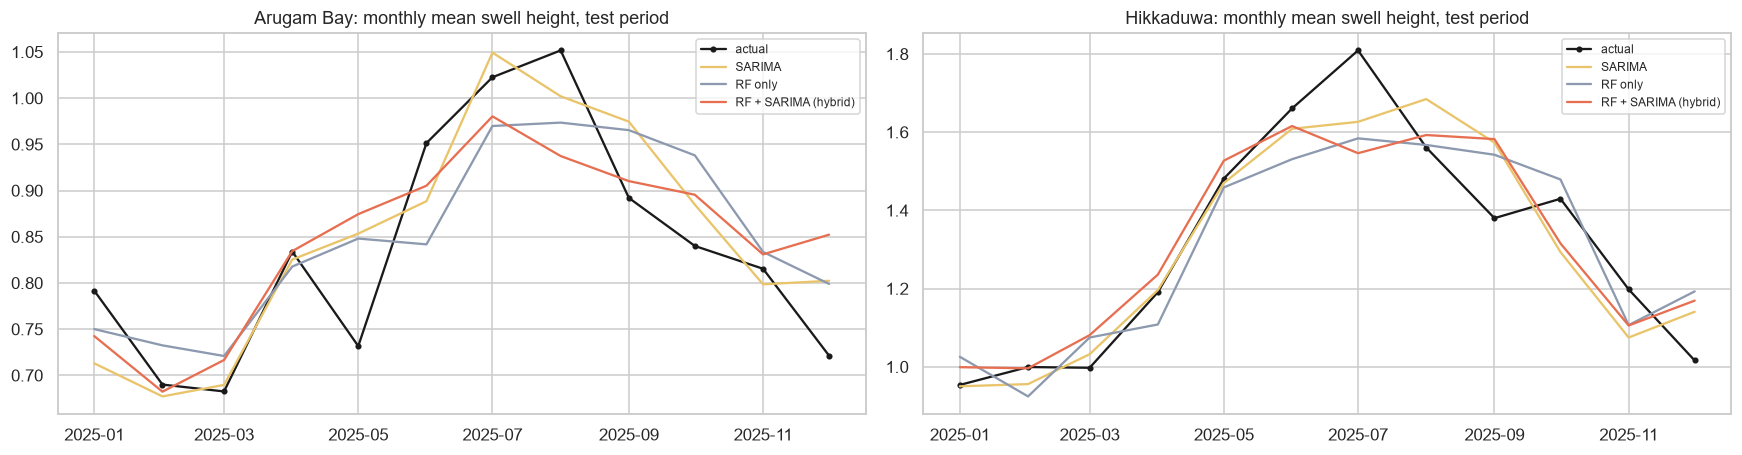

In [19]:
monthly = (raw.set_index("time").groupby("spot")[["swell_wave_height_max", "wind_speed_10m_max"]]
              .resample("MS").mean().reset_index())
sarima_rows, sarima_preds = [], []
for spot, d in monthly.groupby("spot"):
    d = d.set_index("time").asfreq("MS")
    y = d["swell_wave_height_max"].interpolate()
    y_tr = y[y.index < TEST_START]
    best = None
    for order in [(1, 0, 0), (1, 0, 1), (2, 0, 0), (0, 0, 1)]:
        for sorder in [(1, 1, 1, 12), (0, 1, 1, 12), (1, 1, 0, 12)]:
            try:
                r = SARIMAX(y_tr, order=order, seasonal_order=sorder, trend="n").fit(disp=False)
                if best is None or r.aic < best[0]: best = (r.aic, order, sorder, r)
            except Exception:
                pass
    aic, order, sorder, res = best
    full = res.apply(y)                                    # same parameters, filter through all months
    yhat = full.get_prediction(dynamic=False).predicted_mean   # one-step-ahead forecasts
    df_ = pd.DataFrame({"y": y, "sarima": yhat, "wind": d["wind_speed_10m_max"].interpolate()})
    df_["resid"] = df_["y"] - df_["sarima"]
    for l in [1, 2, 12]: df_[f"resid_lag{l}"] = df_["resid"].shift(l)
    df_["y_lag1"], df_["y_lag12"], df_["wind_lag1"] = df_["y"].shift(1), df_["y"].shift(12), df_["wind"].shift(1)
    df_["m_sin"], df_["m_cos"] = F.sincos(df_.index.month, 12)
    df_ = df_.iloc[13:].dropna()
    hx = ["resid_lag1", "resid_lag2", "resid_lag12", "wind_lag1", "m_sin", "m_cos", "sarima"]
    rx = ["y_lag1", "y_lag12", "wind_lag1", "m_sin", "m_cos"]
    tr_, te_ = df_[df_.index < TEST_START], df_[df_.index >= TEST_START]
    rf_res = RandomForestRegressor(300, min_samples_leaf=3, random_state=SEED).fit(tr_[hx], tr_["resid"])
    rf_only = RandomForestRegressor(300, min_samples_leaf=3, random_state=SEED).fit(tr_[rx], tr_["y"])
    out = pd.DataFrame({"time": te_.index, "spot": spot, "actual": te_["y"].values, "SARIMA": te_["sarima"].values,
                        "RF only": rf_only.predict(te_[rx]),
                        "RF + SARIMA (hybrid)": te_["sarima"].values + rf_res.predict(te_[hx])})
    sarima_preds.append(out)
    for mname in ["SARIMA", "RF only", "RF + SARIMA (hybrid)"]:
        sarima_rows.append({"spot": spot, "model": mname,
                            "RMSE": mean_squared_error(out["actual"], out[mname]) ** 0.5,
                            "MAE": mean_absolute_error(out["actual"], out[mname]), "R2": r2_score(out["actual"], out[mname]),
                            "SARIMA order": f"{order}x{sorder}"})
    joblib.dump({"sarima_params": res.params, "order": order, "seasonal_order": sorder, "rf_residual": rf_res,
                 "features": hx}, f"models/hybrid_rf_sarima_{F.SPOTS[spot]['key']}.pkl", compress=3)
hyb1 = pd.DataFrame(sarima_rows); hyb1_pred = pd.concat(sarima_preds, ignore_index=True)
display(hyb1.round(4))
fig, axes = plt.subplots(1, 2, figsize=(16, 4.3))
for ax, (spot, d) in zip(axes, hyb1_pred.groupby("spot")):
    ax.plot(d["time"], d["actual"], "k-o", label="actual", ms=3)
    for c, col in zip(["SARIMA", "RF only", "RF + SARIMA (hybrid)"], ["#e9c46a", "#8d99ae", "#e76f51"]):
        ax.plot(d["time"], d[c], label=c, color=col)
    ax.set_title(f"{spot}: monthly mean swell height, test period"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Interpretation.** With only about 39 training months, SARIMA alone is the best monthly forecaster (Arugam Bay RMSE 0.061 m,
R² 0.74; Hikkaduwa RMSE 0.109 m, R² 0.85) because the monsoon cycle is very regular and SARIMA's seasonal term captures
it directly. The RF residual correction did **not** help here (RMSE 0.072 and 0.119): after differencing and lags
there are only about 26 training rows for the RF, which is too few to learn reliable corrections, so it adds noise.
This is an honest negative result: a hybrid only helps when there is enough data for the second model to learn the
leftover pattern.

## 16. Hybrid 2: **RF + ANN (MLP)** regression of tomorrow's swell height (m)
Random Forest is strong on threshold-type rules and interactions. A neural network (MLP) produces *smooth* functions.
We blend them, and choose the blend weight on the **last training year** (validation) so the test set is not touched.

Blend weight for RF chosen on validation year: 0.8


,model,RMSE,MAE,R2
0,Persistence (today's swell),0.1921,0.1379,0.7520
1,Random Forest,0.1692,0.1256,0.8077
2,MLP (ANN),0.2045,0.1552,0.7189
3,RF + MLP average (50/50),0.1739,0.1300,0.7969
4,RF + MLP weighted (w_RF=0.8),0.1675,0.1242,0.8114


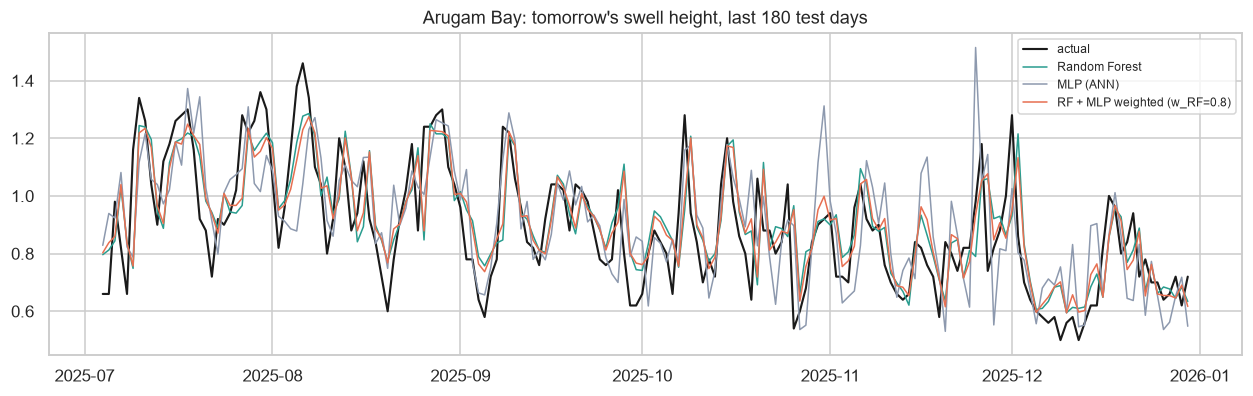

['models/hybrid_rf_mlp.pkl']

In [20]:
yr_tr, yr_te = train["swell_h_tomorrow"], test["swell_h_tomorrow"]
val_start = TEST_START - pd.DateOffset(years=1)
fit_m, val_m = train["time"] < val_start, train["time"] >= val_start
def make_rf(): return RandomForestRegressor(n_estimators=300, min_samples_leaf=2, max_features=0.5, n_jobs=1, random_state=SEED)
def make_mlp(): return make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=(64, 32), alpha=1e-3,
                                     learning_rate_init=1e-3, early_stopping=True, max_iter=500, random_state=SEED))
# 1) choose the blend weight on validation
rf_v, mlp_v = make_rf().fit(X_train[fit_m], yr_tr[fit_m]), make_mlp().fit(X_train[fit_m], yr_tr[fit_m])
pr_v, pm_v = rf_v.predict(X_train[val_m]), mlp_v.predict(X_train[val_m])
ws = np.round(np.arange(0, 1.01, 0.1), 1)
val_rmse = [mean_squared_error(yr_tr[val_m], w * pr_v + (1 - w) * pm_v) ** 0.5 for w in ws]
W = float(ws[int(np.argmin(val_rmse))]); print("Blend weight for RF chosen on validation year:", W)
# 2) refit on all training data, evaluate on test
rf_reg, mlp_reg = make_rf().fit(X_train, yr_tr), make_mlp().fit(X_train, yr_tr)
pr, pm = rf_reg.predict(X_test), mlp_reg.predict(X_test)
preds2 = {"Persistence (today's swell)": test["swell_wave_height_max"].values, "Random Forest": pr, "MLP (ANN)": pm,
          "RF + MLP average (50/50)": 0.5 * pr + 0.5 * pm, f"RF + MLP weighted (w_RF={W})": W * pr + (1 - W) * pm}
hyb2 = pd.DataFrame([{"model": k, "RMSE": mean_squared_error(yr_te, v) ** 0.5, "MAE": mean_absolute_error(yr_te, v),
                      "R2": r2_score(yr_te, v)} for k, v in preds2.items()])
display(hyb2.round(4))
hyb2_pred = pd.DataFrame({"time": test["time"].values, "spot": test["spot"].values, "actual": yr_te.values,
                          **{k: v for k, v in preds2.items()}})
fig, ax = plt.subplots(figsize=(14, 3.8))
d = hyb2_pred[(hyb2_pred.spot == "Arugam Bay")].iloc[-180:]
ax.plot(d["time"], d["actual"], "k-", label="actual", lw=1.4)
for k, c in [("Random Forest", "#2a9d8f"), ("MLP (ANN)", "#8d99ae"), (f"RF + MLP weighted (w_RF={W})", "#e76f51")]:
    ax.plot(d["time"], d[k], label=k, color=c, lw=1)
ax.set_title("Arugam Bay: tomorrow's swell height, last 180 test days"); ax.legend(fontsize=8); plt.show()
joblib.dump({"rf": rf_reg, "mlp": mlp_reg, "w_rf": W, "features": FEATS}, "models/hybrid_rf_mlp.pkl", compress=3)

**Interpretation.** For daily swell-height regression the hybrid works. The blend weight chosen on the 2024 validation year was
w_RF = 0.8, and the **RF + MLP weighted** model has the lowest test error (RMSE 0.1675 m, R² 0.811), slightly better
than Random Forest alone (0.1692) and clearly better than the MLP alone (0.2045) and persistence (0.1921). The MLP is
weaker on its own, but its errors are different from the RF's, so a small share of it improves the forecast.

## 17. Conclusions and limitations

* **Ensembles beat single models.** Every ensemble beats the single decision tree, and Random Forest is the best
  classifier (F1 0.705, accuracy 0.845, ROC-AUC 0.883), beating the persistence baseline (F1 0.667, ROC-AUC 0.767).
* **Why:** bagging and RF reduce the tree's variance (train/test gap 23 → 14.5 points), boosting reduces bias, and
  stacking learns to lean on RF and logistic regression.
* **What drives good surf:** today's conditions (persistence), swell alignment with the break, swell period and the
  offshore wind component. The two coasts have opposite monsoon seasons.
* **Hybrids:** RF + MLP improved daily swell-height forecasts (RMSE 0.1675 vs 0.1692 for RF). RF + SARIMA did not
  beat plain SARIMA with only about 4 years of monthly data.
* **Limitations:** only about 4 years of swell data (Open-Meteo marine data starts Oct 2021); gridded model data, not
  buoy measurements at the break; the label is rule-based and ignores tide, sandbanks and crowd; one test year.
* **Future work:** longer wave records (e.g. ERA5 swell partitions), tide data, and real surfer reports as labels.

## 18. Save models and results for the dashboard

In [21]:
for name, mdl in models.items():
    fn = "models/" + name.lower().replace(" ", "_") + ".pkl"
    joblib.dump(mdl, fn, compress=3)
for name, mdl in tuned.items():
    joblib.dump(mdl, "models/" + name.lower().replace(" ", "_") + "_tuned.pkl", compress=3)
sizes = {f: round(os.path.getsize("models/" + f) / 1e6, 2) for f in sorted(os.listdir("models"))}
print("Model file sizes (MB):", sizes)

metrics.reset_index().to_csv("results/metrics.csv", index=False)
pred = test[["time", "spot", "good_surf_tomorrow"]].rename(columns={"good_surf_tomorrow": "actual"}).copy()
for k, v in proba_test.items(): pred[k] = v
pred.to_csv("results/test_predictions.csv", index=False)
test[["time", "spot"] + FEATS + ["good_surf_tomorrow", "swell_h_tomorrow", "wind_direction_10m_dominant",
     "swell_wave_direction_dominant"]].loc[:, lambda d: ~d.columns.duplicated()].to_csv("results/test_features.csv", index=False)
oob_curve.to_csv("results/oob_curve.csv", index=False); m_curve.to_csv("results/max_features.csv", index=False)
imp.to_csv("results/importance.csv", index=False); dt_depth.to_csv("results/dt_depth.csv", index=False)
tuning.to_csv("results/tuning.csv", index=False); stack_cmp.reset_index(names="variant").to_csv("results/stacking_cv.csv", index=False)
hyb1.to_csv("results/hybrid_sarima_metrics.csv", index=False); hyb1_pred.to_csv("results/hybrid_sarima_preds.csv", index=False)
hyb2.to_csv("results/hybrid_mlp_metrics.csv", index=False); hyb2_pred.to_csv("results/hybrid_mlp_preds.csv", index=False)
thr.to_csv("results/threshold_best.csv", index=False)
daily = raw.copy(); daily["good_surf"] = F.good_surf(daily)
daily.drop(columns=["month"], errors="ignore").to_csv("results/data_daily.csv", index=False)
model_files = {n: n.lower().replace(" ", "_") + ".pkl" for n in models}
model_files.update({n + " (tuned)": n.lower().replace(" ", "_") + "_tuned.pkl" for n in tuned})
json.dump({"features": FEATS, "test_start": str(TEST_START.date()), "rules": F.RULES, "best_model": best_name,
           "model_files": model_files, "n_train": len(train), "n_test": len(test),
           "date_min": str(raw.time.min().date()), "date_max": str(raw.time.max().date())},
          open("results/meta.json", "w"), indent=2)
print("Saved", len(os.listdir("results")), "result files.")

Model file sizes (MB): {'.gitkeep': 0.0, 'adaboost.pkl': 0.03, 'bagged_trees.pkl': 1.32, 'decision_tree.pkl': 0.01, 'gradient_boosting.pkl': 0.11, 'hybrid_rf_mlp.pkl': 7.73, 'hybrid_rf_sarima_arugam.pkl': 0.06, 'hybrid_rf_sarima_hikkaduwa.pkl': 0.06, 'lightgbm.pkl': 0.59, 'random_forest.pkl': 3.77, 'random_forest_tuned.pkl': 1.84, 'soft_voting.pkl': 3.1, 'stacking.pkl': 3.01, 'xgboost.pkl': 0.16, 'xgboost_tuned.pkl': 0.04}
Saved 17 result files.
